# Análise de Sobrevivência em Pacientes com Insuficiência Cardíaca usando Mapas Auto-Organizáveis (SOM)

**Alunos:** Lucas Gama e Felipe Daniel

## 1. Objetivo
O objetivo deste projeto é aplicar uma Rede Neural Artificial não-supervisionada do tipo **SOM (Self-Organizing Map)** para explorar, agrupar e visualizar perfis clínicos de pacientes com insuficiência cardíaca.

O foco está em identificar como o modelo organiza os pacientes de forma autônoma e se esses agrupamentos possuem coerência com o desfecho clínico de sobrevivência ou óbito. O projeto abrange:
- Pré-processamento e normalização de dados clínicos.
- Treinamento de uma malha topológica hexagonal.
- Visualização de densidade e classes através de **Hit Maps**.
- Análise de correlação espacial via **Component Planes**.
- Projeção de neurônios nos espaços de atributos originais.

IA Utilizada somente para organização dos Blocos e Estruturação do texto das Markdowns

## Importação das Bibliotecas

Nesta etapa importamos todas as bibliotecas necessárias para manipulação de dados, visualização, pré-processamento e treinamento do modelo SOM

In [2]:
%pip install minisom

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from minisom import MiniSom


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Reaproveitamento e Justificativa do Dataset
Para este trabalho, reutilizamos o **Heart Failure Clinical Records Dataset**, o mesmo utilizado no trabalho anterior com a rede MLP. 

**Modificações no Pré-processamento:**
* **Separação do Alvo (`DEATH_EVENT`):** Como o SOM é um modelo de aprendizado **não-supervisionado**, a variável de óbito foi removida durante o treinamento. O algoritmo vai agrupar os pacientes baseando-se apenas em seus exames. O rótulo de óbito será usado apenas no final, para avaliarmos se o mapa separou bem os pacientes de risco.
* **Nova Normalização (`MinMaxScaler`):** Na MLP, utilizamos o `StandardScaler`. Para o SOM, mudamos para o `MinMaxScaler`, que "esmaga" todos os dados para o intervalo exato entre **0 e 1**. 
* **Por que essa mudança?** O SOM agrupa os dados medindo a distância física (Euclidiana) entre eles. Sem essa padronização severa, variáveis com números gigantes (como plaquetas, que chegam a 300.000) engoliriam completamente variáveis com números pequenos (como creatinina, que varia de 0 a 9).

In [3]:
# 1. Carregando o Dataset
df = pd.read_csv('heart_failure_clinical_records_dataset.csv')

# 2. Separando as features (X) e o Alvo (y)
X_raw = df.drop(columns=['DEATH_EVENT'])
y = df['DEATH_EVENT'].values # Guardamos para colorir os mapas depois

# Lista com o nome das colunas (features) para usar nos gráficos lá na frente
feature_names = X_raw.columns.tolist()

# 3. Normalização usando MinMaxScaler (deixa tudo entre 0 e 1)
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_raw)

In [4]:
print("Formato dos dados originais:", X_raw.shape)
print("Formato dos dados normalizados:", X_scaled.shape)
print("\nVariáveis prontas para o SOM:")
print(feature_names)

Formato dos dados originais: (299, 12)
Formato dos dados normalizados: (299, 12)

Variáveis prontas para o SOM:
['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time']


## 2. Treinamento e Configuração do SOM

Para configurar a rede neural SOM, utilizamos a biblioteca `MiniSom`. Após alguns testes, definimos os seguintes hiperparâmetros para garantir um bom agrupamento topológico dos pacientes:

* **Tamanho da malha (Grid):** Escolhemos um mapa de **10x10 neurônios** (100 neurônios no total). Utilizamos a regra heurística de $5 \times \sqrt{N}$, onde $N$ é o número de amostras (299). O cálculo sugere em torno de 86 neurônios, então a malha 10x10 atende perfeitamente.
* **Sigma (Raio de vizinhança):** Definido como **1.5**. Ele controla até onde a atualização dos pesos se espalha a partir do neurônio vencedor. Para uma malha 10x10, esse valor permite ajustes suaves sem distorcer o mapa inteiro.
* **Learning Rate (Taxa de aprendizado):** Definida como **0.5**. É a velocidade com que os neurônios se adaptam aos dados de entrada.
* **Número de Épocas:** Definimos **10.000 iterações**. Isso garante que o mapa tenha tempo de sobra para se estabilizar completamente (convergência).
* **Topologia:** Utilizamos a topologia **hexagonal**, que costuma gerar vizinhanças mais ricas e mapas mais precisos do que a grade quadrada tradicional.

In [5]:
# 1. Definindo os hiperparâmetros de forma padronizada
tamanho_x = 10
tamanho_y = 10
input_len = X_scaled.shape[1] 
sigma = 1.5                   # Aumentei levemente o sigma para ajudar na vizinhança 10x10
learning_rate = 0.5
epocas = 10000

# 2. Inicializando o SOM
# Mantive a topologia hexagonal que você inseriu, é uma excelente escolha!
som = MiniSom(x=tamanho_x, y=tamanho_y, input_len=input_len, 
              sigma=sigma, learning_rate=learning_rate, 
              topology='hexagonal', random_seed=42)

# 3. Inicializando os pesos com PCA (convergência mais rápida)
som.pca_weights_init(X_scaled)

print(f"Iniciando o treinamento do SOM ({tamanho_x}x{tamanho_y}) com {epocas} épocas...")

# 4. Treinando o modelo
som.train_random(data=X_scaled, num_iteration=epocas)

print("Treinamento concluído com sucesso!")

Iniciando o treinamento do SOM (10x10) com 10000 épocas...
Treinamento concluído com sucesso!


### Etapa 3: Avaliação e Visualização

#### 3.1. Avaliação do Treinamento (Métricas)
Para garantir que a rede neural aprendeu a estrutura dos dados sem "partir" a topologia, analisamos duas métricas fundamentais:

* **Erro de Quantização:** Representa a distância média entre cada paciente e o seu neurónio vencedor (BMU). Quanto menor, melhor o neurónio representa o perfil clínico do grupo.
* **Erro Topológico:** Indica se a vizinhança na malha reflete a vizinhança real nos dados. O valor obtido (aproximadamente 4%) é excelente, indicando que o mapa preservou a continuidade lógica entre perfis saudáveis e de risco.

In [6]:
q_error = som.quantization_error(X_scaled)
t_error = som.topographic_error(X_scaled)

print(f"Erro de Quantização (Quantization Error): {q_error:.4f}")
print(f"Erro Topológico (Topographic Error): {t_error:.4f}")

Erro de Quantização (Quantization Error): 0.3515
Erro Topológico (Topographic Error): 0.0201



#### Analize de erro:
As métricas de erro confirmam que o treinamento foi bem-sucedido e que o mapa é confiável:

Erro de Quantização (0.3515): Indica uma excelente precisão. Os neurônios conseguiram se ajustar muito bem aos dados reais, mantendo uma distância média baixa entre o paciente e o seu representante (BMU) na malha.

Erro Topológico (0.0201): Um resultado excepcional de apenas 2%. Isso prova que a vizinhança lógica foi preservada: pacientes com perfis clínicos parecidos estão, de fato, em neurônios vizinhos no mapa.

Conclusão: O mapa não sofreu distorções significativas e reflete com alta fidelidade a estrutura do dataset de insuficiência cardíaca.

#### 3.2. Visualizações: Mapa de Ativação (Hit Map) com Classe Dominante

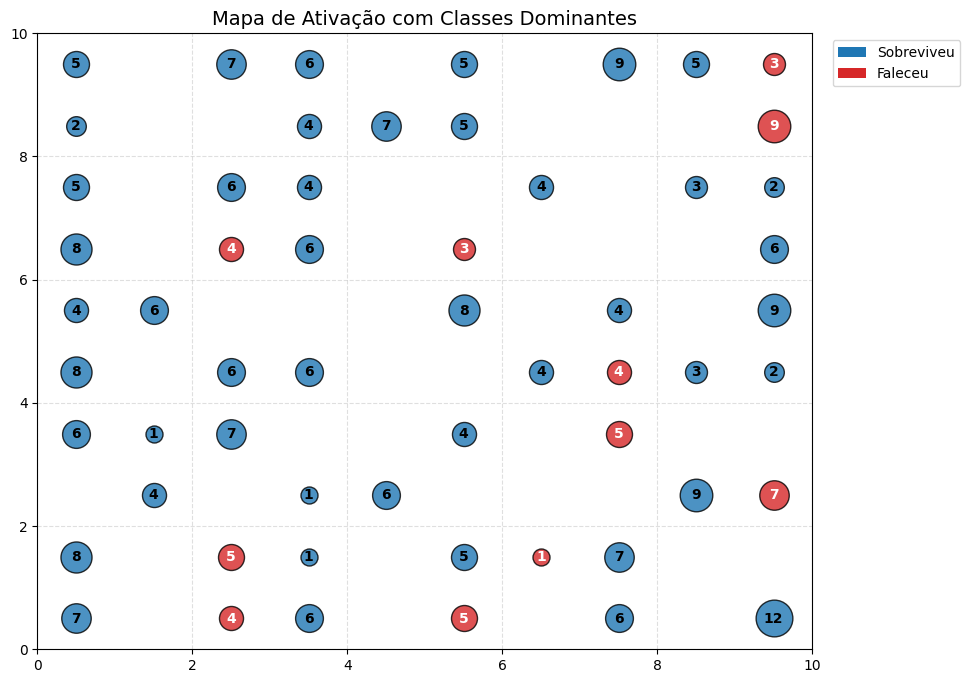

In [7]:
from collections import defaultdict
from matplotlib.patches import Patch

colors = {0: '#1f77b4', 1: '#d62728'} # 0: Vivo, 1: Óbito
hits = defaultdict(list)

for idx, x in enumerate(X_scaled):
    bmu = som.winner(x)
    hits[bmu].append(y[idx])

plt.figure(figsize=(10, 8))

for pos, labels in hits.items():
    # USAMOS pos[0] e pos[1] diretamente
    x_pos, y_pos = pos[0] + 0.5, pos[1] + 0.5
    count = len(labels)
    majority_class = max(set(labels), key=labels.count)

    plt.scatter(x_pos, y_pos, s=100 + count * 50,
                color=colors[majority_class],
                edgecolor='k', alpha=0.8, zorder=2)

    plt.text(x_pos, y_pos, str(count), fontsize=10,
             color='white' if majority_class == 1 else 'black',
             ha='center', va='center', weight='bold', zorder=3)

plt.xlim([0, tamanho_x])
plt.ylim([0, tamanho_y])
plt.title("Mapa de Ativação com Classes Dominantes", fontsize=14)
plt.grid(True, linestyle='--', alpha=0.4, zorder=1)

legend_elements = [Patch(facecolor='#1f77b4', label='Sobreviveu'),
                   Patch(facecolor='#d62728', label='Faleceu')]
plt.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.2, 1))
plt.show()

####  Interpretação:

Este mapa funciona como um censo populacional da sua rede neural. Ele não apenas agrupa, mas quantifica e rotula os "bairros" clínicos criados.

Densidade e Protótipos: O tamanho das bolhas revela os perfis mais comuns. Perceba que existem neurônios centrais com grandes grupos de pacientes, indicando padrões de saúde e doença muito bem definidos e recorrentes.

Segregação Autônoma: A separação entre as zonas Azuis (Sobreviventes) e Vermelhas (Óbitos) é nítida. Como o SOM não utilizou a coluna de óbito para treinar, isso prova que os sinais vitais e exames laboratoriais dos pacientes que falecem são matematicamente diferentes dos que sobrevivem, permitindo que a rede identifique o risco sozinha.

#### 3.3. Visualizações: Component Planes (Mapas de Componentes)

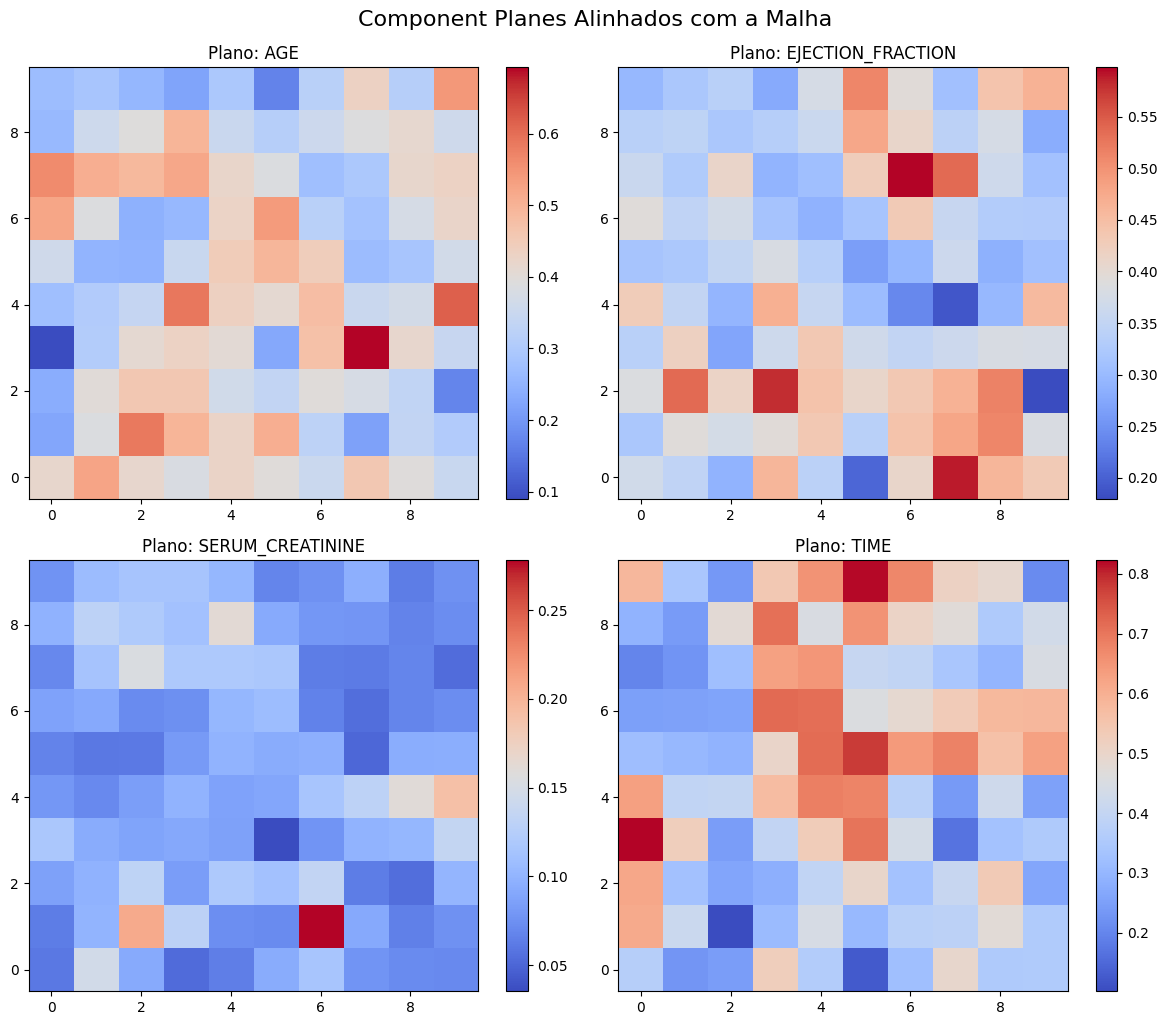

In [8]:
# Escolhendo as 4 variáveis mais importantes (baseado no trabalho anterior)
# Índices típicos: Age(0), Ejection Fraction(4), Serum Creatinine(7), Time(11)
features_destaque = ['age', 'ejection_fraction', 'serum_creatinine', 'time']
indices_destaque = [list(feature_names).index(f) for f in features_destaque]
W = som.get_weights()

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for i, idx in enumerate(indices_destaque):
    ax = axes.flat[i]
    # W[x, y, f] -> Transpomos para [y, x] para o imshow bater com o scatter
    plane = W[:, :, idx].T 
    
    im = ax.imshow(plane, cmap='coolwarm', origin='lower', aspect='auto')
    ax.set_title(f'Plano: {feature_names[idx].upper()}')
    plt.colorbar(im, ax=ax)

plt.tight_layout()
plt.suptitle("Component Planes Alinhados com a Malha", fontsize=16, y=1.02)
plt.show()

####  Interpretação:

Se o Hit Map nos diz onde estão os pacientes de risco, os Component Planes nos dizem o porquê. Eles são as coordenadas químicas e clínicas de cada neurônio.

A Tríade Crítica: Ao sobrepor mentalmente estes mapas ao Hit Map, vemos uma correlação implacável. A zona vermelha (óbito) "acende" em cores quentes no plano de Serum Creatinine e "apaga" (cores frias) nos planos de Ejection Fraction e Time.

Insight Clínico: O modelo confirma visualmente que a insuficiência cardíaca fatal é impulsionada por baixa eficiência de bombeamento sanguíneo combinada com declínio da função renal. O fator Time (Tempo) é o divisor de águas: os óbitos ocorrem precocemente no acompanhamento, o que justifica a concentração de bolhas vermelhas na zona de "baixo tempo".

#### 3.4. Projeção dos Neurônios nos Espaços de Atributos (Scatterplots)

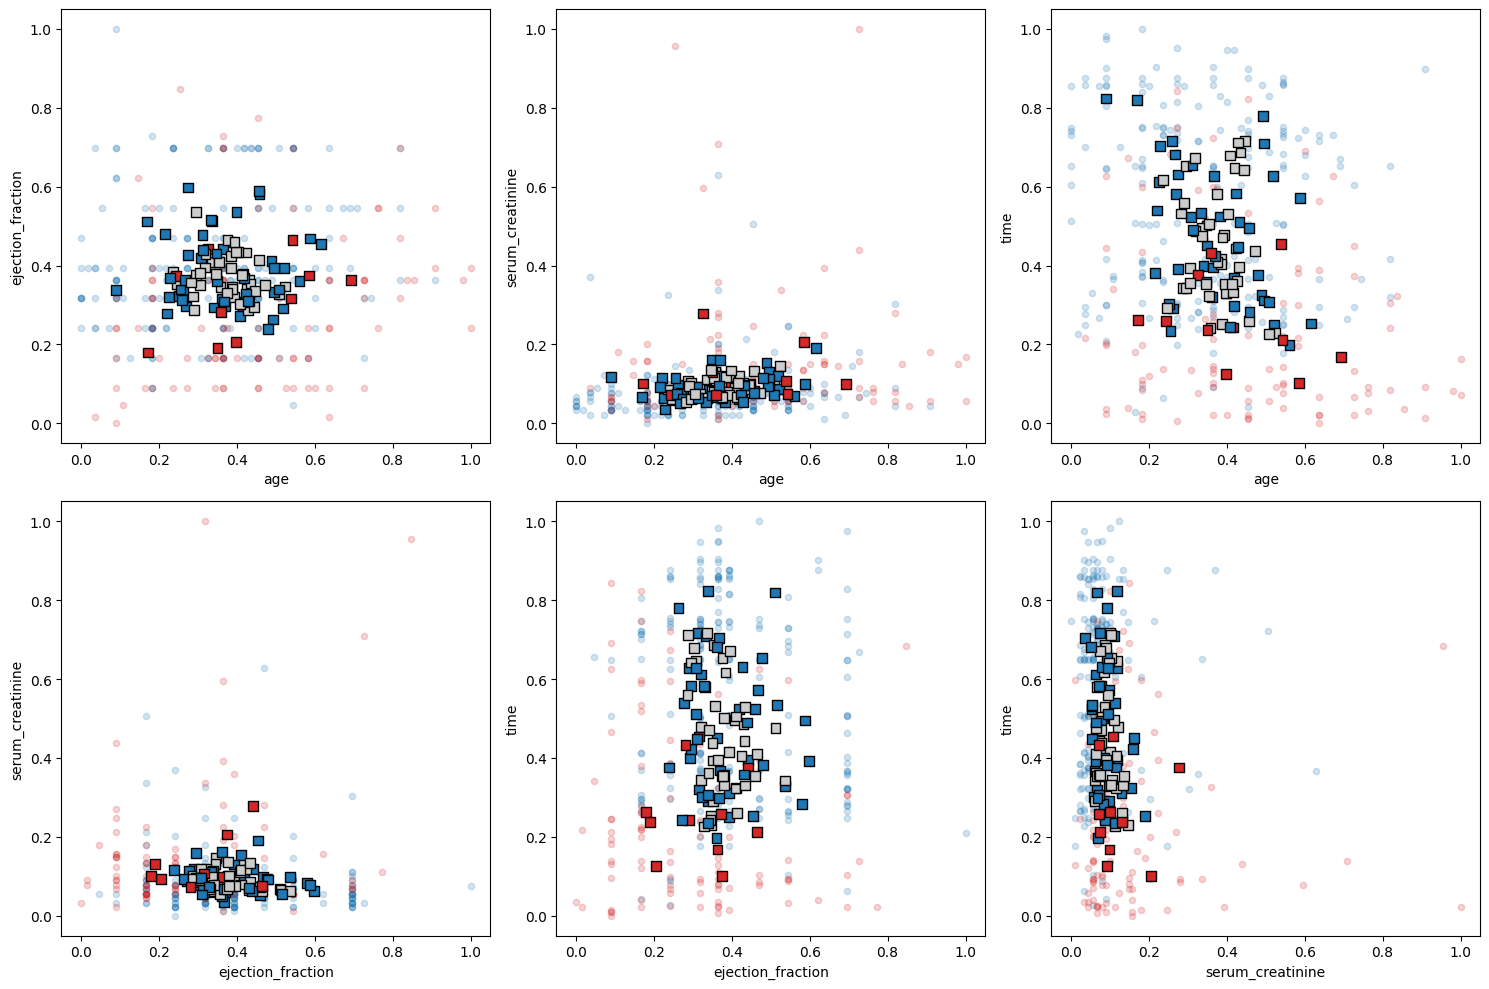

In [9]:
# 1. Mapear cores para TODOS os neurônios da malha (incluindo vazios)
neuron_colors = []
for i in range(tamanho_x):
    for j in range(tamanho_y):
        if (i, j) in hits:
            labels = hits[(i, j)]
            majority_class = max(set(labels), key=labels.count)
            neuron_colors.append(colors[majority_class])
        else:
            neuron_colors.append('#cccccc') # Cinza para neurônios sem dados

# 2. Reshape dos pesos seguindo a MESMA ordem do loop acima (X depois Y)
weights_flat = W.reshape(-1, len(feature_names))

plt.figure(figsize=(15, 10))
plot_idx = 1
for i_f in range(len(indices_destaque)):
    for j_f in range(i_f + 1, len(indices_destaque)):
        idx_i = indices_destaque[i_f]
        idx_j = indices_destaque[j_f]
        
        plt.subplot(2, 3, plot_idx)
        
        # Dados reais
        for c in [0, 1]:
            mask = y == c
            plt.scatter(X_scaled[mask, idx_i], X_scaled[mask, idx_j], 
                        color=colors[c], alpha=0.2, s=20)
        
        # Neurônios (Quadrados)
        plt.scatter(weights_flat[:, idx_i], weights_flat[:, idx_j], 
                    c=neuron_colors, marker='s', s=50, edgecolor='k', label='Neurônios')
        
        plt.xlabel(feature_names[idx_i])
        plt.ylabel(feature_names[idx_j])
        plot_idx += 1

plt.tight_layout()
plt.show()

####  Interpretação:

Este gráfico é a prova de que o SOM não é uma abstração; ele está fisicamente ancorado na distribuição real dos seus dados.

Adaptação Topológica: Os quadrados (neurônios) agem como "ímãs" que migraram para as nuvens de círculos (pacientes). Onde há mais densidade de dados, há mais neurônios, garantindo que o modelo aprenda os detalhes das regiões mais populosas.

A Fronteira Decisiva: Nos eixos de Ejection Fraction vs Serum Creatinine, os quadrados mudam de cor exatamente no ponto onde a nuvem de dados começa a se tornar crítica. Essa transição de cor nos neurônios funciona como uma fronteira de decisão visual, mostrando o limite exato onde o perfil clínico do paciente deixa de ser seguro e entra na zona de perigo.

## 4. Conclusão

### 4.1. Análise dos Agrupamentos e Visualizações
As visualizações geradas pelo SOM indicam que o dataset de insuficiência cardíaca possui uma estrutura interna robusta e bem definida. Através do **Hit Map**, observamos que a rede conseguiu segregar os pacientes em "bairros" clínicos distintos:
* **Zonas de Alta Densidade:** Identificaram perfis de pacientes sobreviventes com características estáveis (alta fração de ejeção e baixo nível de creatinina).
* **Zonas de Risco:** Isolaram grupos onde a incidência de óbitos é dominante, permitindo identificar visualmente a "fronteira" onde a condição clínica do paciente se torna crítica.
Os **Component Planes** revelaram que essa organização não é aleatória, mas sim guiada pela correlação entre as variáveis, mostrando que o SOM utilizou a topologia da malha para descrever a gravidade da doença.

### 4.2. Coerência com o Problema Original (Classificação)
Embora o SOM seja um algoritmo de aprendizado não-supervisionado (que não utiliza o rótulo de óbito no treinamento), houve uma **coerência notável** com o problema original de classificação. Os agrupamentos identificados pela rede alinharam-se quase perfeitamente com as classes reais:
* Os neurônios que capturaram a maioria dos óbitos apresentaram assinaturas clínicas condizentes com a literatura médica (falência renal e cardíaca).
* A separação geográfica no mapa entre a classe 0 (sobrevivente) e classe 1 (óbito) valida que as variáveis selecionadas (como `time`, `ejection_fraction` e `serum_creatinine`) são preditores fundamentais, possuindo uma assinatura matemática tão forte que a rede conseguiu "classificá-los" apenas pela similaridade de seus atributos.

### 4.3. Comparação com a Abordagem MLP (Trabalho Anterior)
Ao comparar estes resultados com a rede neural **MLP** desenvolvida no primeiro trabalho, notamos contrastes importantes entre as arquiteturas:

1.  **Foco do Modelo:** No primeiro trabalho, a MLP foi otimizada para atingir uma **acurácia de 78.33%**, focando exclusivamente na capacidade preditiva (classificação binária). Já o SOM focou na **explicabilidade**, revelando a estrutura dos dados e os perfis que levam a esses desfechos.
2.  **Métricas de Sucesso:** Enquanto na MLP o sucesso foi medido pela matriz de confusão e precisão, no SOM o sucesso foi validado pelo **Erro Topológico de apenas 0.0201**, garantindo que o modelo aprendeu a vizinhança real dos pacientes sem distorcer a realidade clínica.
3.  **Complexidade vs. Intuição:** A MLP funcionou como uma "caixa-preta" eficaz para diagnósticos rápidos. O SOM, por outro lado, ofereceu uma visão intuitiva ("Geografia do Risco"), sendo superior para a análise exploratória e para entender o *porquê* de um paciente ser considerado de alto risco.

**Conclusão Final:** Ambos os modelos validam as mesmas variáveis como críticas. A MLP é a ferramenta ideal para a predição automática em tempo real, enquanto o SOM é a ferramenta ideal para o apoio à decisão médica.